# EDA та baseline-моделі для корекції похибки квантових схем

Цей notebook виконує наступний етап проєкту після збору [синтетичного датасету](../data/README.md):
перевірка якості даних, розвідувальний аналіз (EDA), побудова та оцінка baseline-моделей
(`DummyRegressor`, `LinearRegression`/`Ridge`, `RandomForestRegressor`) для передбачення поправки
`delta = ideal_z0 - noisy_z0`, та перевірка узагальнення на рівні шуму, якого модель не бачила під час навчання.

Нейромережі навмисно не використовуються на цьому етапі — спочатку перевіряємо, наскільки добре
працюють прості моделі, відповідно до завдання.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

df = pd.read_csv("../data/synthetic_expectations.csv")
df.head()

,circuit_id,split,qubits,layers,seed,ry_abs_mean,rz_abs_mean,cx_count,circuit_depth,noise_profile,shots,z0_ones,ideal_z0,noisy_z0,delta
0,q2_l2_s00,train,2,2,0,1.1050,2.2572,1,5,amplitude_damping_high,1024,34,0.9191,0.9336,-0.0145
1,q2_l2_s00,train,2,2,0,1.1050,2.2572,1,5,amplitude_damping_low,1024,38,0.9191,0.9258,-0.0067
2,q2_l2_s00,train,2,2,0,1.1050,2.2572,1,5,depolarizing_high,1024,69,0.9191,0.8652,0.0539
3,q2_l2_s00,train,2,2,0,1.1050,2.2572,1,5,depolarizing_low,1024,49,0.9191,0.9043,0.0148
4,q2_l2_s00,train,2,2,0,1.1050,2.2572,1,5,fake_lagos,1024,202,0.9191,0.6055,0.3137


## 1. Перевірка якості датасету

Перевіряємо пропуски, дублікати та узгодженість поділу на train/validation/test
(жоден `circuit_id` не повинен потрапляти в кілька частин одночасно, оскільки варіанти
однієї схеми за різними профілями шуму мають лишатись разом).

In [2]:
print("Розмір датасету:", df.shape)
print("\nПропуски по колонках:")
print(df.isnull().sum())

print("\nПовні дублікати рядків:", df.duplicated().sum())
print("Дублікати (circuit_id, noise_profile):", df.duplicated(subset=["circuit_id", "noise_profile"]).sum())

leak = df.groupby("circuit_id")["split"].nunique()
print("\ncircuit_id, що зустрічаються у >1 частині (train/val/test):", (leak > 1).sum())

print("\nРозмір частин:")
print(df.groupby("split")["circuit_id"].nunique(), "(унікальних circuit_id)")
print(df["split"].value_counts())

print("\nУнікальні значення shots:", df["shots"].unique())

Розмір датасету: (1800, 15)

Пропуски по колонках:
circuit_id       0
split            0
qubits           0
layers           0
seed             0
ry_abs_mean      0
rz_abs_mean      0
cx_count         0
circuit_depth    0
noise_profile    0
shots            0
z0_ones          0
ideal_z0         0
noisy_z0         0
delta            0
dtype: int64

Повні дублікати рядків: 0
Дублікати (circuit_id, noise_profile): 0

circuit_id, що зустрічаються у >1 частині (train/val/test): 0

Розмір частин:
split
test           24
train         192
validation     24
Name: circuit_id, dtype: int64 (унікальних circuit_id)
split
train         1440
validation     180
test           180
Name: count, dtype: int64

Унікальні значення shots: [1024]


**Висновок з перевірки:** пропусків і дублікатів немає, жодна схема (`circuit_id`) не потрапляє
одночасно в кілька частин — поділ коректний і зафіксований ще на етапі генерації даних
(`split_seeds` у `manifest.json`). Колонка `shots` стала (1024 для всіх рядків), тому дослідити
залежність похибки від кількості shots на цьому датасеті неможливо — це варто зазначити як
обмеження і, за потреби, згенерувати окремі дані з різною кількістю shots.

## 2. Розподіл цільової змінної `delta`

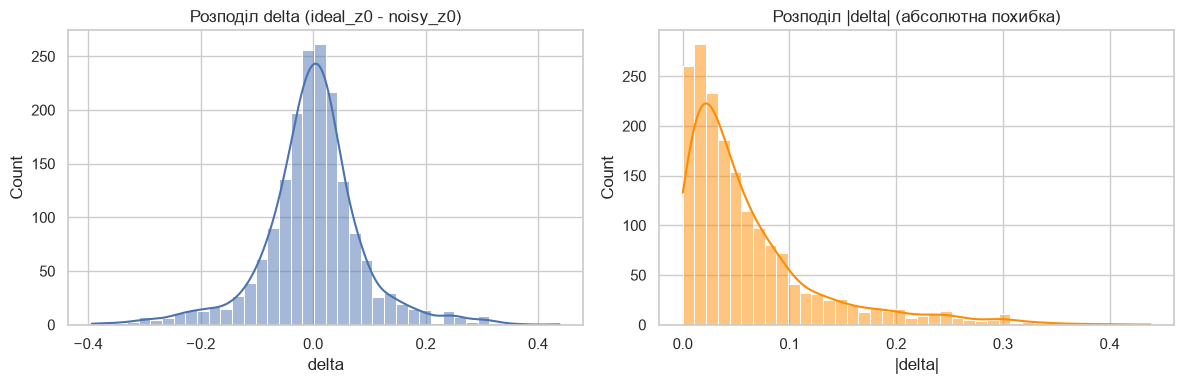

count   1800.0000
mean      -0.0002
std        0.0898
min       -0.3935
25%       -0.0398
50%        0.0017
75%        0.0402
max        0.4385
Name: delta, dtype: float64

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["delta"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Розподіл delta (ideal_z0 - noisy_z0)")
axes[0].set_xlabel("delta")

sns.histplot(df["delta"].abs(), bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Розподіл |delta| (абсолютна похибка)")
axes[1].set_xlabel("|delta|")

plt.tight_layout()
plt.show()

df["delta"].describe()

## 3. Залежність похибки від рівня шуму, кількості shots та глибини схеми

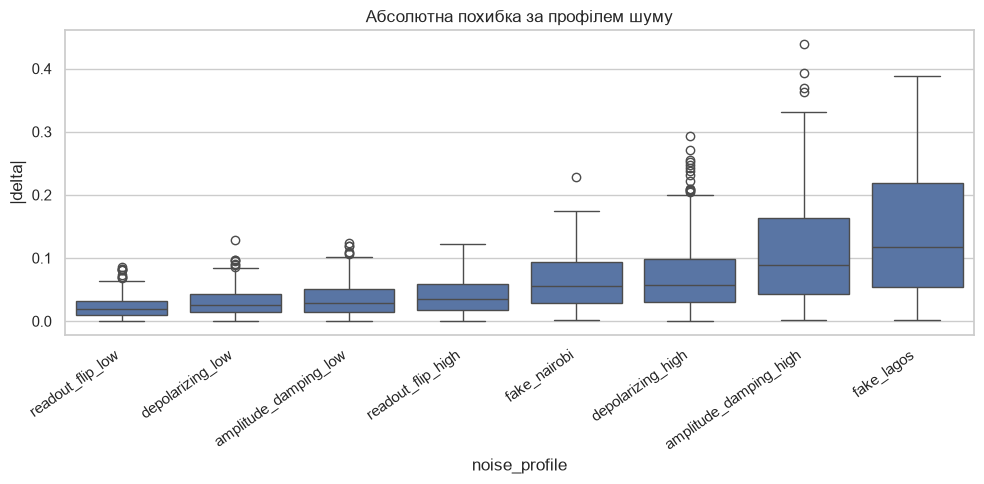

In [4]:
plt.figure(figsize=(10, 5))
order = df.groupby("noise_profile")["delta"].apply(lambda s: s.abs().mean()).sort_values().index
sns.boxplot(data=df, x="noise_profile", y=df["delta"].abs(), order=order)
plt.xticks(rotation=35, ha="right")
plt.ylabel("|delta|")
plt.title("Абсолютна похибка за профілем шуму")
plt.tight_layout()
plt.show()

In [5]:
print("Кількість shots стала для всього датасету (1024), тому пряму залежність")
print("похибки від кількості shots на цих даних перевірити не можна.")
print("Непряма оцінка шуму вимірювання (shot noise) видно через розкид всередині кожного профілю,")
print("але це не замінює експерименту зі зміною shots.")

Кількість shots стала для всього датасету (1024), тому пряму залежність
похибки від кількості shots на цих даних перевірити не можна.
Непряма оцінка шуму вимірювання (shot noise) видно через розкид всередині кожного профілю,
але це не замінює експерименту зі зміною shots.


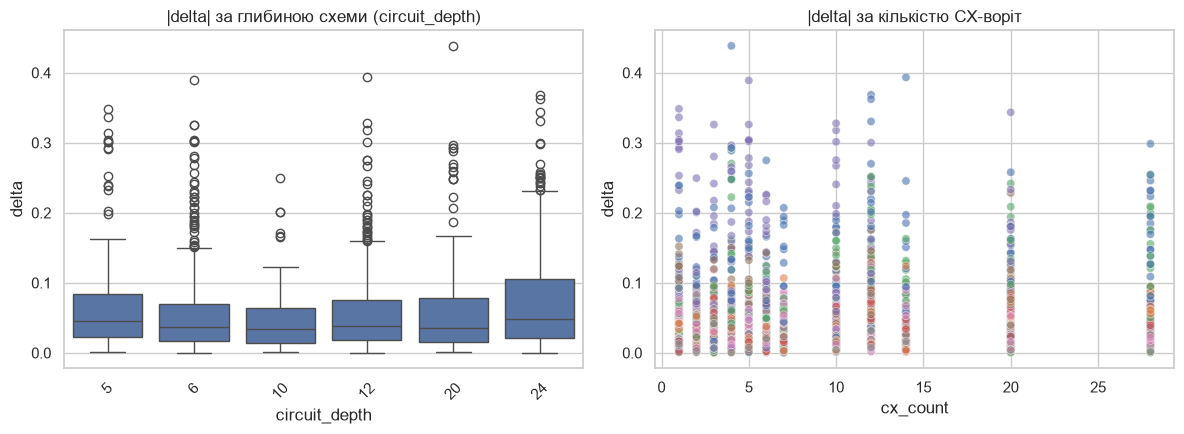

Кореляція структурних характеристик схеми з |delta|:
circuit_depth    0.0911
layers           0.0868
cx_count         0.0411
qubits          -0.0342
Name: abs_delta, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x="circuit_depth", y=df["delta"].abs(), ax=axes[0])
axes[0].set_title("|delta| за глибиною схеми (circuit_depth)")
axes[0].tick_params(axis="x", rotation=45)

sns.scatterplot(data=df, x="cx_count", y=df["delta"].abs(), hue="noise_profile", alpha=0.6, ax=axes[1], legend=False)
axes[1].set_title("|delta| за кількістю CX-воріт")

plt.tight_layout()
plt.show()

corr_cols = ["qubits", "layers", "cx_count", "circuit_depth"]
corr = df[corr_cols].assign(abs_delta=df["delta"].abs()).corr()["abs_delta"].drop("abs_delta")
print("Кореляція структурних характеристик схеми з |delta|:")
print(corr.sort_values(ascending=False))

**Висновок з EDA:** похибка явно залежить від профілю шуму (ручні `_high` профілі та `fake_lagos`
дають найбільшу |delta|, `_low` профілі — найменшу). Залежність від глибини/розміру схеми (`cx_count`,
`circuit_depth`, `qubits`) значно слабша і менш монотонна — це очікувано, бо глибина на цьому датасеті
варіюється в невеликому діапазоні (2–4 шари), а шум уже закладений окремими явними профілями, а не лише
накопиченням по глибині.

## 4. Ознаки, ціль та розділення train/validation/test

Ознаки моделі: `noisy_z0`, `qubits`, `layers`, `ry_abs_mean`, `rz_abs_mean`, `cx_count`, `circuit_depth`,
`noise_profile` (категоріальна). Ціль: `delta`. `ideal_z0`, `z0_ones`, `seed`, `split`, `circuit_id`
у модель не подаються (per `data/README.md`).

Використовуємо вже зафіксований і перевірений у розділі 1 поділ `train`/`validation`/`test`
(80% / 10% / 10% за `circuit_id`) — його не потрібно перераховувати, оскільки варіанти однієї
схеми (за профілями шуму) вже гарантовано лишаються в одній частині.

In [7]:
num_features = ["noisy_z0", "qubits", "layers", "ry_abs_mean", "rz_abs_mean", "cx_count", "circuit_depth"]
cat_features = ["noise_profile"]
features = num_features + cat_features
target = "delta"

train = df[df["split"] == "train"]
val = df[df["split"] == "validation"]
test = df[df["split"] == "test"]

print(f"train: {len(train)}, validation: {len(val)}, test: {len(test)}")

train: 1440, validation: 180, test: 180


## 5. Baseline-моделі

Порівнюємо чотири моделі: `DummyRegressor` (завжди передбачає середнє delta з train — нижня межа
якості), `LinearRegression`, `Ridge` та `RandomForestRegressor`. Усі моделі навчені на `train`,
підібрані (неявно, без тюнінгу гіперпараметрів на цьому етапі) та оцінені на `validation` і `test`.

In [8]:
def make_pipeline(model):
    pre = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)],
        remainder="passthrough",
    )
    return Pipeline([("pre", pre), ("model", model)])


models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42),
}

def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "R2": r2_score(y, pred),
    }

fitted = {}
rows = []
for name, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(train[features], train[target])
    fitted[name] = pipe
    for split_name, split_df in [("validation", val), ("test", test)]:
        metrics = evaluate(pipe, split_df[features], split_df[target])
        rows.append({"model": name, "split": split_name, **metrics})

results = pd.DataFrame(rows)
results

,model,split,MAE,RMSE,R2
0,Dummy (mean),validation,0.0498,0.0689,-0.0026
1,Dummy (mean),test,0.0622,0.0900,-0.0109
2,Linear Regression,validation,0.0474,0.0648,0.1149
3,Linear Regression,test,0.0511,0.0734,0.3276
4,Ridge (alpha=1.0),validation,0.0474,0.0647,0.1161
5,Ridge (alpha=1.0),test,0.0511,0.0734,0.3277
6,Random Forest,validation,0.0421,0.0639,0.1394
7,Random Forest,test,0.0332,0.0490,0.6997


In [9]:
raw_mae_test = test["delta"].abs().mean()
raw_rmse_test = (test["delta"] ** 2).mean() ** 0.5
print(f"Еталон без виправлення (просто лишити noisy_z0 як є) на test: MAE={raw_mae_test:.4f}, RMSE={raw_rmse_test:.4f}")

comparison_test = results[results["split"] == "test"].drop(columns="split").set_index("model").sort_values("MAE")
comparison_test

Еталон без виправлення (просто лишити noisy_z0 як є) на test: MAE=0.0621, RMSE=0.0899


,MAE,RMSE,R2
model,,,
Random Forest,0.0332,0.0490,0.6997
Ridge (alpha=1.0),0.0511,0.0734,0.3277
Linear Regression,0.0511,0.0734,0.3276
Dummy (mean),0.0622,0.0900,-0.0109


## 6. Передбачені vs реальні значення `delta` (test)

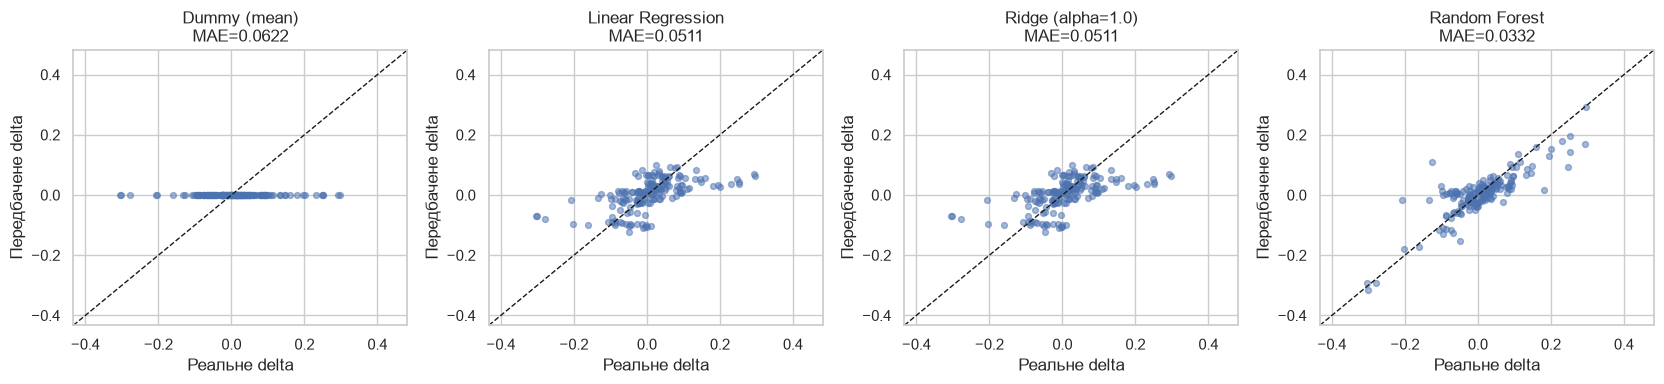

In [10]:
fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 4))
lims = (df["delta"].min() * 1.1, df["delta"].max() * 1.1)

for ax, (name, pipe) in zip(axes, fitted.items()):
    pred = pipe.predict(test[features])
    ax.scatter(test[target], pred, alpha=0.5, s=18)
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Реальне delta")
    ax.set_ylabel("Передбачене delta")
    mae = mean_absolute_error(test[target], pred)
    ax.set_title(f"{name}\nMAE={mae:.4f}")

plt.tight_layout()
plt.show()

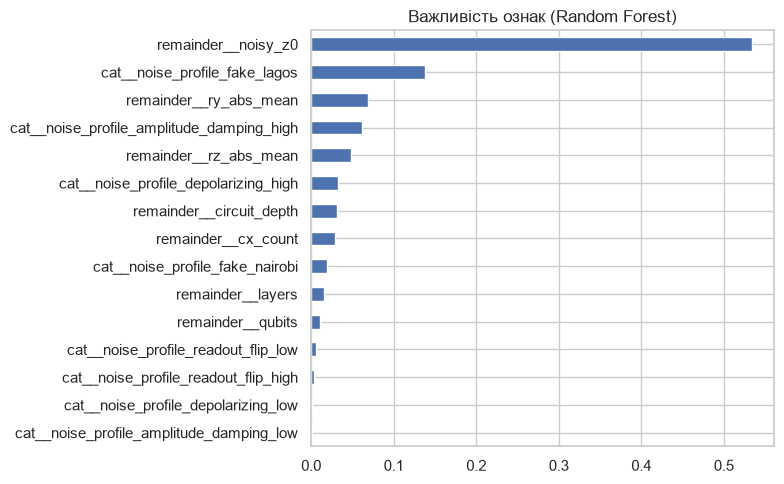

In [11]:
rf_pipe = fitted["Random Forest"]
importances = rf_pipe.named_steps["model"].feature_importances_
feature_names = rf_pipe.named_steps["pre"].get_feature_names_out()

imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
imp.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Важливість ознак (Random Forest)")
plt.tight_layout()
plt.show()

**Висновок з порівняння моделей:** `Random Forest` дає помітно нижчу MAE/RMSE і вищий R² за
`Linear Regression`/`Ridge` та за `DummyRegressor`, тобто між ознаками схеми й поправкою `delta` є
нелінійний сигнал, який проста лінійна модель вловлює лише частково. Усі навчені моделі покращують
результат порівняно з відсутністю корекції (`raw MAE` вище). Найважливіша ознака для Random Forest —
`noise_profile` (через one-hot кодування), що узгоджується з висновком EDA про домінуючий вплив
профілю шуму над структурними характеристиками схеми.

## 7. Перевірка узагальнення на рівні шуму, якого не було під час навчання

Попередній поділ перевіряє узагальнення за **схемами** (`circuit_id`). Тут перевіряємо інший тип
узагальнення: чи модель, навчена лише на "низьких" рівнях шуму (`*_low`) та на знімках реальних
бекендів (`fake_lagos`, `fake_nairobi`), здатна коригувати похибку на "високих" рівнях шуму
(`*_high`), яких взагалі не було в навчальній вибірці.

Тут навмисно допускається повторення `circuit_id` між train і test — перевіряється узагальнення
за рівнем шуму, а не за схемою (це вже перевірено в розділі 5).

In [12]:
high_levels = ["amplitude_damping_high", "depolarizing_high", "readout_flip_high"]

train_noise_gen = df[~df["noise_profile"].isin(high_levels)]
test_noise_gen = df[df["noise_profile"].isin(high_levels)]

print(f"train (без 'high' рівнів шуму): {len(train_noise_gen)} рядків")
print(f"test (лише 'high' рівні, не бачені моделлю): {len(test_noise_gen)} рядків")

rf_gen = make_pipeline(RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42))
rf_gen.fit(train_noise_gen[features], train_noise_gen[target])
pred_gen = rf_gen.predict(test_noise_gen[features])

mae_gen = mean_absolute_error(test_noise_gen[target], pred_gen)
rmse_gen = mean_squared_error(test_noise_gen[target], pred_gen) ** 0.5
r2_gen = r2_score(test_noise_gen[target], pred_gen)
raw_mae_gen = test_noise_gen["delta"].abs().mean()

print(f"\nRandom Forest на невідомому рівні шуму: MAE={mae_gen:.4f}, RMSE={rmse_gen:.4f}, R2={r2_gen:.4f}")
print(f"Без корекції (raw) на тих самих рядках: MAE={raw_mae_gen:.4f}")
print(f"Для порівняння, MAE Random Forest на звичайному test (бачені рівні шуму): {comparison_test.loc['Random Forest', 'MAE']:.4f}")

train (без 'high' рівнів шуму): 1080 рядків
test (лише 'high' рівні, не бачені моделлю): 720 рядків



Random Forest на невідомому рівні шуму: MAE=0.0613, RMSE=0.0877, R2=0.2281
Без корекції (raw) на тих самих рядках: MAE=0.0738
Для порівняння, MAE Random Forest на звичайному test (бачені рівні шуму): 0.0332


**Висновок з перевірки узагальнення:** на незнайомому (вищому) рівні шуму якість моделі помітно
падає порівняно зі звичайним test (вищі MAE/RMSE, нижчий R²), але модель все одно дає покращення
порівняно з відсутністю корекції (`raw MAE`). Це очікувано: модель частково екстраполює залежність
"більше шуму → більша поправка", підхоплену через `noisy_z0` та структурні ознаки схеми, але без
прикладів конкретного рівня шуму в навчанні екстраполяція неточна. Для продакшн-використання це
означає, що модель варто перенавчати або донавчати щоразу, коли з'являється новий, раніше не бачений
профіль/рівень шуму.

## Підсумкові висновки

1. **Якість даних:** датасет чистий — без пропусків і дублікатів, поділ train/validation/test
   коректно згрупований за `circuit_id`, тому варіанти однієї схеми не витікають між вибірками.
2. **EDA:** похибка `delta` переважно визначається профілем шуму (ручні `_high` профілі та знімок
   `fake_lagos` дають найбільшу похибку); структурні характеристики схеми (глибина, кількість CX)
   впливають значно слабше в межах цього датасету. Залежність від кількості `shots` перевірити
   неможливо — вона стала (1024) для всіх прикладів.
3. **Baseline-моделі:** `Random Forest` суттєво перевершує `DummyRegressor` і лінійні моделі за MAE,
   RMSE та R² на відкладеному test; лінійні моделі також покращують результат відносно відсутності
   корекції, але слабше за Random Forest — сигнал у даних переважно нелінійний.
4. **Узагальнення:** модель непогано узагальнюється на нові *схеми* того самого рівня шуму, але
   значно гірше — на *рівень шуму*, якого взагалі не бачила під час навчання. Це важливе обмеження
   для подальшої роботи з реальними даними пристрою (де калібрування й рівень шуму можуть відрізнятися
   від синтетичних профілів).

**Наступні кроки (поза межами цього етапу):** спробувати градієнтний бустинг (XGBoost/LightGBM) і
просту нейромережу, як зазначено в пропозиції проєкту, порівняти їх з Random Forest за MAE і часом
інференсу; за наявності доступу — додати окремий тест на даних реального пристрою.